# Claude Code pull requests
**Paper:** Watanabe et al. 2025 – On the Use of Agentic Coding: An Empirical Study of Pull Requests on GitHub
**Data:** https://github.com/mmikuu/OnTheUseOfAgenticCoding

**What is in the data:** Pull requests made **with Claude Code** (APR = agentic PR) and human PRs (HPR) in the same projects: merged, closed or open, and for merged ones whether humans had to **revise** them (with the type of each revision: fix, docs, refactor…).

**One row of the main table =** one Claude Code pull request

This notebook has 3 parts:
1. **First look** – the files, some lines, all the columns, the size.
2. **Data-science view** – size, dates, **numbers per AI agent**, **how the agent is involved** (tables saved in `tables/`).
3. **Charts** – what kind of change · fixes per AI agent · who wrote the fix · how fast the fix comes · extra (saved in `charts/`).

In [1]:
import sys, os, json
sys.path.insert(0, "..")          # to find common.py in the parent folder
from common import *

## 0. Get the data

In [2]:
root = get_repo("https://github.com/mmikuu/OnTheUseOfAgenticCoding", "ontheuseofagenticcoding")
D = os.path.join(root, "Data")

Data folder: ../../data/04_Watanabe_ClaudeCode/ontheuseofagenticcoding


## 1. First look
### Files in the repository

In [3]:
list_files(root).head(25)

,file,size_MB
0,Data/commit_details/APR-commit-details.csv,1.67
1,Data/APR-MERGED.csv,0.19
2,Data/require_revision/APR-no-require-revision.csv,0.16
3,Data/classification/Revision-APR(RQ4).csv,0.03
4,Data/APR-CLOSED.csv,0.03
5,Data/require_revision/APR-require-revision.csv,0.02
6,Data/APR-OPEN.csv,0.01


### Main table: all Claude Code PRs (merged + closed + open)

In [4]:
parts = []
for state, f in [("merged", "APR-MERGED.csv"), ("closed", "APR-CLOSED.csv"), ("open", "APR-OPEN.csv")]:
    t = pd.read_csv(os.path.join(D, f)); t["outcome"] = state; parts.append(t)
apr = pd.concat(parts, ignore_index=True)
_ = overview(apr, "Claude Code PRs")

**Claude Code PRs** — **797 rows × 18 columns** (0.4 MB in memory)

*First 5 lines:*

,owner,repo_name,url,pull_number,stars,total_commits,changed_files,added_lines,deleted_lines,first_commit_sha,merge_commit_sha,base_commit_sha,pr_final_head_sha,author_login,created_at,merged_at,time_to_merge,outcome
0,giselles-ai,giselle,https://github.com/giselles-ai/giselle/pull/789,789,126,2,5,62,52,a8f5d99f5ca735f1d17d9ab3c4fdc344bd2f91ae,3905bf3899cdf6a487272ebe7399405434ae744a,851aab199ed6e42eef94b6a76fc06b29188b43a0,028c2a74e9a98d6aa0fc5246627c924c1527646b,toyamarinyon,2025-04-30T12:36:52Z,2025-04-30T14:28:11Z,1:51:19,merged
1,making,yavi,https://github.com/making/yavi/pull/463,463,810,1,1,252,20,f6c7487a032c3b4361e8f051b746803fbea4010e,dc7add976c7fc4f034ab5b1b766626143d4f81bb,b2e1b05a67566ae98023984223cfbf74d4be0f58,f6c7487a032c3b4361e8f051b746803fbea4010e,making,2025-04-27T10:06:49Z,2025-04-27T23:52:06Z,13:45:17,merged
2,Tiberriver256,mcp-server-azure-devops,https://github.com/Tiberriver256/mcp-server-azure-devops...,181,229,2,13,835,6,4a9af76d55cce290c5f2c352f7249e1584ae69a9,d2fde5f94280f08056f94b613a673d4bbe9c0192,dde58f857c787bc884179e432e20d8655d999672,98077fbc1b14362fed48539cdf86b651674bca6d,ap9035,2025-04-23T07:56:17Z,2025-04-23T12:30:27Z,4:34:10,merged
3,honeycombio,honeycomb-mcp,https://github.com/honeycombio/honeycomb-mcp/pull/61,61,23,2,3,41,13,7a047c18d8f549c9545e1cfc8b9e96504b11b6da,7e4afc49a29314dc080259cbdd64377b3af5684d,3a099ca9088878bf2c5326731582364b36e6bfcb,28c7bffd3c4463fde7015f93589c22b731c9da25,austinlparker,2025-04-25T20:34:29Z,2025-04-25T20:39:03Z,0:04:34,merged
4,alexei-led,k8s-mcp-server,https://github.com/alexei-led/k8s-mcp-server/pull/4,4,140,5,16,1345,916,b6a44f3dba7d155bfabced0f91f1a113d6055c3f,ff041329ced6e9954efcadd9b68f8572bbf26fbd,ba6b1684adaeb0d665351cab78f3fec64866203b,479bb6d9543fa6f9a4f1ef5ffbebba57995e638e,alexei-led,2025-04-29T08:39:59Z,2025-04-29T08:55:13Z,0:15:14,merged


*All columns:*

,column,type,missing_%,unique,example
0,owner,str,0.0,205,giselles-ai
1,repo_name,str,0.0,238,giselle
2,url,str,0.0,797,https://github.com/giselles-ai/giselle/pull/789
3,pull_number,int64,0.0,552,789
4,stars,int64,0.0,213,126
5,total_commits,int64,0.0,39,2
6,changed_files,int64,0.0,66,5
7,added_lines,int64,0.0,425,62
8,deleted_lines,int64,0.0,232,52
9,first_commit_sha,str,0.0,765,a8f5d99f5ca735f1d17d9ab3c4fdc344bd2f91ae


### Merged PRs that needed a revision, and the type of each revision

In [5]:
rev = pd.read_csv(os.path.join(D, "require_revision", "APR-require-revision.csv"))
norev = pd.read_csv(os.path.join(D, "require_revision", "APR-no-require-revision.csv"))
labels = pd.read_csv(os.path.join(D, "classification", "Revision-APR(RQ4).csv"))
_ = overview(rev, "PRs that needed a revision")
_ = overview(labels, "Revision labels")

**PRs that needed a revision** — **214 rows × 15 columns** (0.0 MB in memory)

*First 5 lines:*

,owner,repo_name,pull_number,url,state,revision_commit,revision_total_additions,revision_total_deletions,revision_total_change_lines,revision_file_change,Co-authored commits number,initial_total_additions,initial_total_deletions,initial_change_lines,initial_file_change
0,567-labs,instructor,1374,https://github.com/567-labs/instructor/pull/1374,MERGED,2,1439,344,1783,8,0,759,50,809,4
1,567-labs,instructor,1375,https://github.com/567-labs/instructor/pull/1375,MERGED,4,1628,1033,2661,9,0,598,97,695,2
2,567-labs,instructor,1399,https://github.com/567-labs/instructor/pull/1399,MERGED,2,168,36,204,2,0,170,6,176,3
3,567-labs,instructor,1479,https://github.com/567-labs/instructor/pull/1479,MERGED,3,61,60,121,1,0,3197,2,3199,19
4,567-labs,instructor,1490,https://github.com/567-labs/instructor/pull/1490,MERGED,16,1016,525,1541,8,6,783,90,873,16


*All columns:*

,column,type,missing_%,unique,example
0,owner,str,0.0,78,567-labs
1,repo_name,str,0.0,87,instructor
2,pull_number,int64,0.0,193,1374
3,url,str,0.0,214,https://github.com/567-labs/instructor/pull/1374
4,state,str,0.0,1,MERGED
5,revision_commit,int64,0.0,19,2
6,revision_total_additions,int64,0.0,125,1439
7,revision_total_deletions,int64,0.0,110,344
8,revision_total_change_lines,int64,0.0,143,1783
9,revision_file_change,int64,0.0,35,8


**Revision labels** — **214 rows × 14 columns** (0.1 MB in memory)

*First 5 lines:*

,owner,repo_name,url,pull_number,commits,state,sha,label1,label2,label3,label4,label5,label6,label7
0,567-labs,instructor,1374,https://github.com/567-labs/instructor/pull/1374,https://github.com/567-labs/instructor/pull/1374/commits/,MERGED,2d48f5b,refactor,feat,NaN,NaN,NaN,NaN,NaN
1,567-labs,instructor,1375,https://github.com/567-labs/instructor/pull/1375,https://github.com/567-labs/instructor/pull/1375/commits/,MERGED,48d144d,test,fix,NaN,NaN,NaN,NaN,NaN
2,567-labs,instructor,1399,https://github.com/567-labs/instructor/pull/1399,https://github.com/567-labs/instructor/pull/1399/commits/,MERGED,35e69d7,docs,NaN,NaN,NaN,NaN,NaN,NaN
3,567-labs,instructor,1479,https://github.com/567-labs/instructor/pull/1479,https://github.com/567-labs/instructor/pull/1479/commits/,MERGED,b44591b,docs,chore,NaN,NaN,NaN,NaN,NaN
4,567-labs,instructor,1490,https://github.com/567-labs/instructor/pull/1490,https://github.com/567-labs/instructor/pull/1490/commits/,MERGED,cdac903,feat,fix,docs,test,NaN,NaN,NaN


*All columns:*

,column,type,missing_%,unique,example
0,owner,str,0.0,78,567-labs
1,repo_name,str,0.0,87,instructor
2,url,int64,0.0,193,1374
3,pull_number,str,0.0,214,https://github.com/567-labs/instructor/pull/1374
4,commits,str,0.0,214,https://github.com/567-labs/instructor/pull/1374/c
5,state,str,0.0,1,MERGED
6,sha,str,0.0,214,2d48f5b
7,label1,str,0.0,9,refactor
8,label2,str,46.7,10,feat
9,label3,str,74.8,9,docs


## 2. Data-science view
### Size and dates

In [6]:
apr["created_at"] = pd.to_datetime(apr["created_at"], utc=True, errors="coerce")
apr["hours_to_merge"] = pd.to_timedelta(apr["time_to_merge"], errors="coerce").dt.total_seconds() / 3600
print("Claude Code PRs :", len(apr), "| repos:", apr["url"].str.extract(r"github\.com/([^/]+/[^/]+)")[0].nunique())
print(apr["outcome"].value_counts().to_dict())
print("Merged PRs studied for revision:", len(rev) + len(norev), "| needed a revision:", len(rev))
print("Dates (merged PRs):", apr.created_at.min().date(), "->", apr.created_at.max().date())

Claude Code PRs : 797 | repos: 240
{'merged': 594, 'closed': 149, 'open': 54}
Merged PRs studied for revision: 475 | needed a revision: 214
Dates (merged PRs): 2025-02-21 -> 2025-04-30


### Numbers per AI agent
This dataset has **one agent only: Claude Code**.

In [7]:
lab = pd.concat([labels[f"label{i}"] for i in range(1, 8)]).dropna()
per_agent = pd.DataFrame([{"agent": "Claude Code", "PRs": len(apr), "merged": (apr.outcome == "merged").sum(),
     "merge_%": round(100 * (apr.outcome == "merged").mean(), 1), "merged_needing_revision": len(rev),
     "revision_commits_labelled_fix": int((lab == "fix").sum()), "median_hours_to_merge": round(apr.hours_to_merge.median(), 1)}])
save_table(per_agent, "per_agent")
per_agent

,agent,PRs,merged,merge_%,merged_needing_revision,revision_commits_labelled_fix,median_hours_to_merge
0,Claude Code,797,594,74.5,214,102,0.9


### How the agent is involved
The PR is **written with Claude Code** (developer + agent). In revised PRs, revision commits are made by the developer, sometimes **with Claude as co-author** (`Co-authored commits number`).

In [8]:
rev["revised_by"] = rev["Co-authored commits number"].gt(0).map({True: "with Claude co-author", False: "human only"})
inv = rev["revised_by"].value_counts().rename_axis("revision commits").reset_index(name="PRs")
save_table(inv, "who_revises")
inv

,revision commits,PRs
0,human only,126
1,with Claude co-author,88


In [9]:
summary_card("Watanabe et al. 2025", "Claude Code PR", len(apr), apr["url"].str.extract(r"github\.com/([^/]+/[^/]+)")[0].nunique(),
             str(apr.created_at.min().date()), str(apr.created_at.max().date()), "Claude Code",
             "Developer writes the PR with Claude Code; revisions by human or with Claude", int(len(rev)))

,
paper,Watanabe et al. 2025
unit (1 row =),Claude Code PR
rows,797
repos,240
first date,2025-02-21
latest date,2025-04-30
agents,Claude Code
how the agent is involved,Developer writes the PR with Claude Code; revisions by h...
fixes of AI code,214


,paper,unit (1 row =),rows,repos,first date,latest date,agents,how the agent is involved,fixes of AI code
0,Watanabe et al. 2025,Claude Code PR,797,240,2025-02-21,2025-04-30,Claude Code,Developer writes the PR with Claude Code; revisions by h...,214


## 3. Charts
### Chart 1 · Type of the revisions made to merged Claude Code PRs

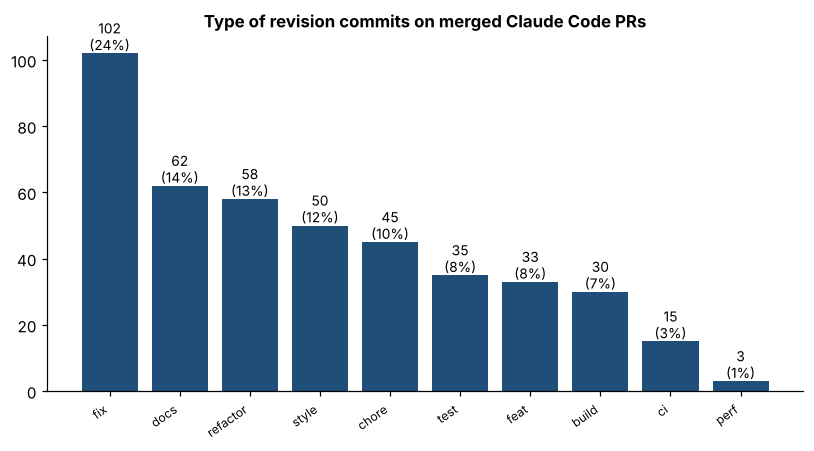

*Exact numbers – Type of revision commits on merged Claude Code PRs*

,number,%
fix,102.0,23.6
docs,62.0,14.3
refactor,58.0,13.4
style,50.0,11.5
chore,45.0,10.4
test,35.0,8.1
feat,33.0,7.6
build,30.0,6.9
ci,15.0,3.5
perf,3.0,0.7


In [10]:
bar(lab.value_counts(), "Type of revision commits on merged Claude Code PRs", "1_revision_types.png", pct=True)

### Chart 2 · Outcome of the Claude Code PRs (one agent only)

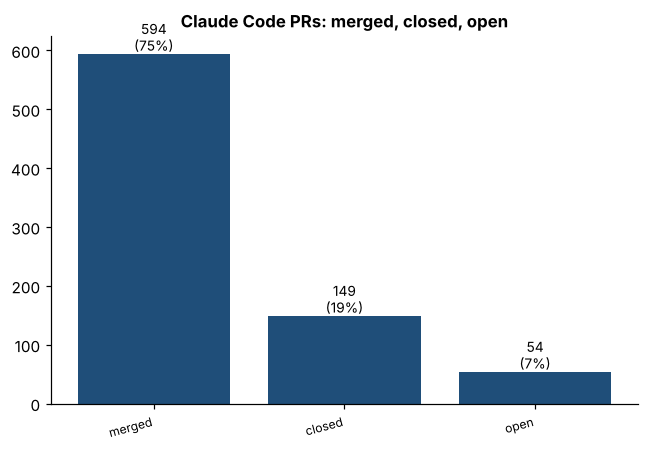

*Exact numbers – Claude Code PRs: merged, closed, open*

,number,%
outcome,,
merged,594.0,74.5
closed,149.0,18.7
open,54.0,6.8
TOTAL,797.0,100.0


In [11]:
bar(apr["outcome"].value_counts(), "Claude Code PRs: merged, closed, open", "2_outcome.png", pct=True)

### Chart 3 · Who made the revisions

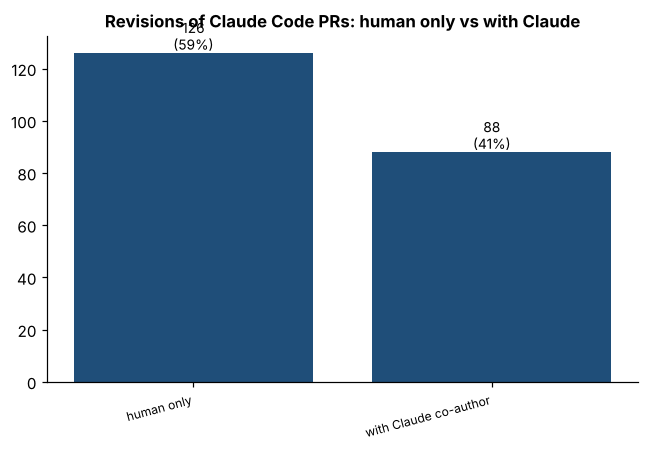

*Exact numbers – Revisions of Claude Code PRs: human only vs with Claude*

,number,%
revised_by,,
human only,126.0,58.9
with Claude co-author,88.0,41.1
TOTAL,214.0,100.0


In [12]:
bar(rev["revised_by"].value_counts(), "Revisions of Claude Code PRs: human only vs with Claude", "3_who_revises.png", pct=True)

### Chart 4 · How fast the PR is merged

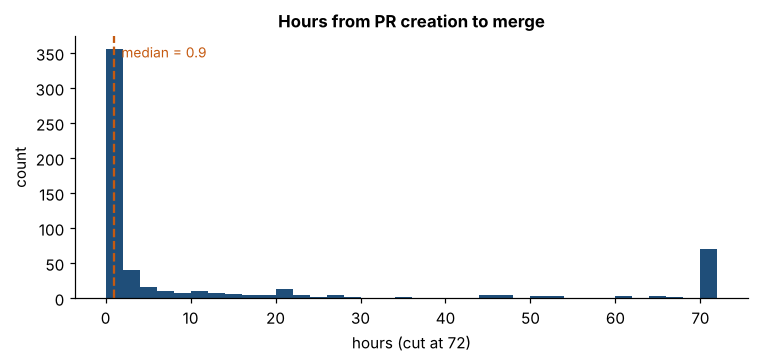

*Exact numbers – Hours from PR creation to merge*

,count,mean,std,min,25%,median,75%,max
hours (cut at 72),593.0,14.06,24.78,0.0,0.1,0.94,12.81,72.0


In [13]:
hist(apr["hours_to_merge"].clip(upper=72), "Hours from PR creation to merge", "4_hours_to_merge.png", "hours (cut at 72)", bins=36)

### Extra · Size of the revisions

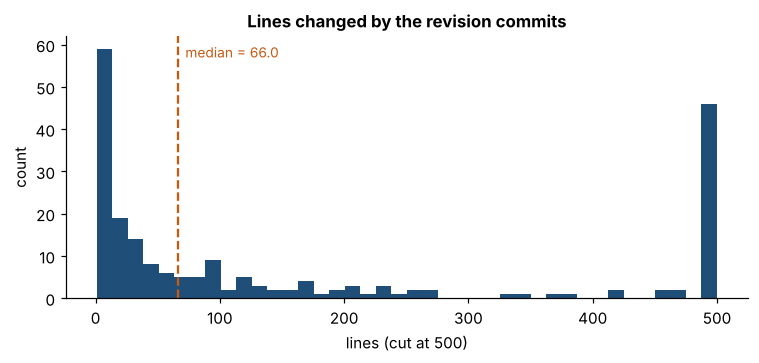

*Exact numbers – Lines changed by the revision commits*

,count,mean,std,min,25%,median,75%,max
lines (cut at 500),214.0,169.83,198.27,1.0,12.0,66.0,361.0,500.0


In [14]:
hist(rev["revision_total_change_lines"].clip(upper=500), "Lines changed by the revision commits", "5_revision_size.png", "lines (cut at 500)", bins=40)

## 4. Final figure (the 4 charts on one page)

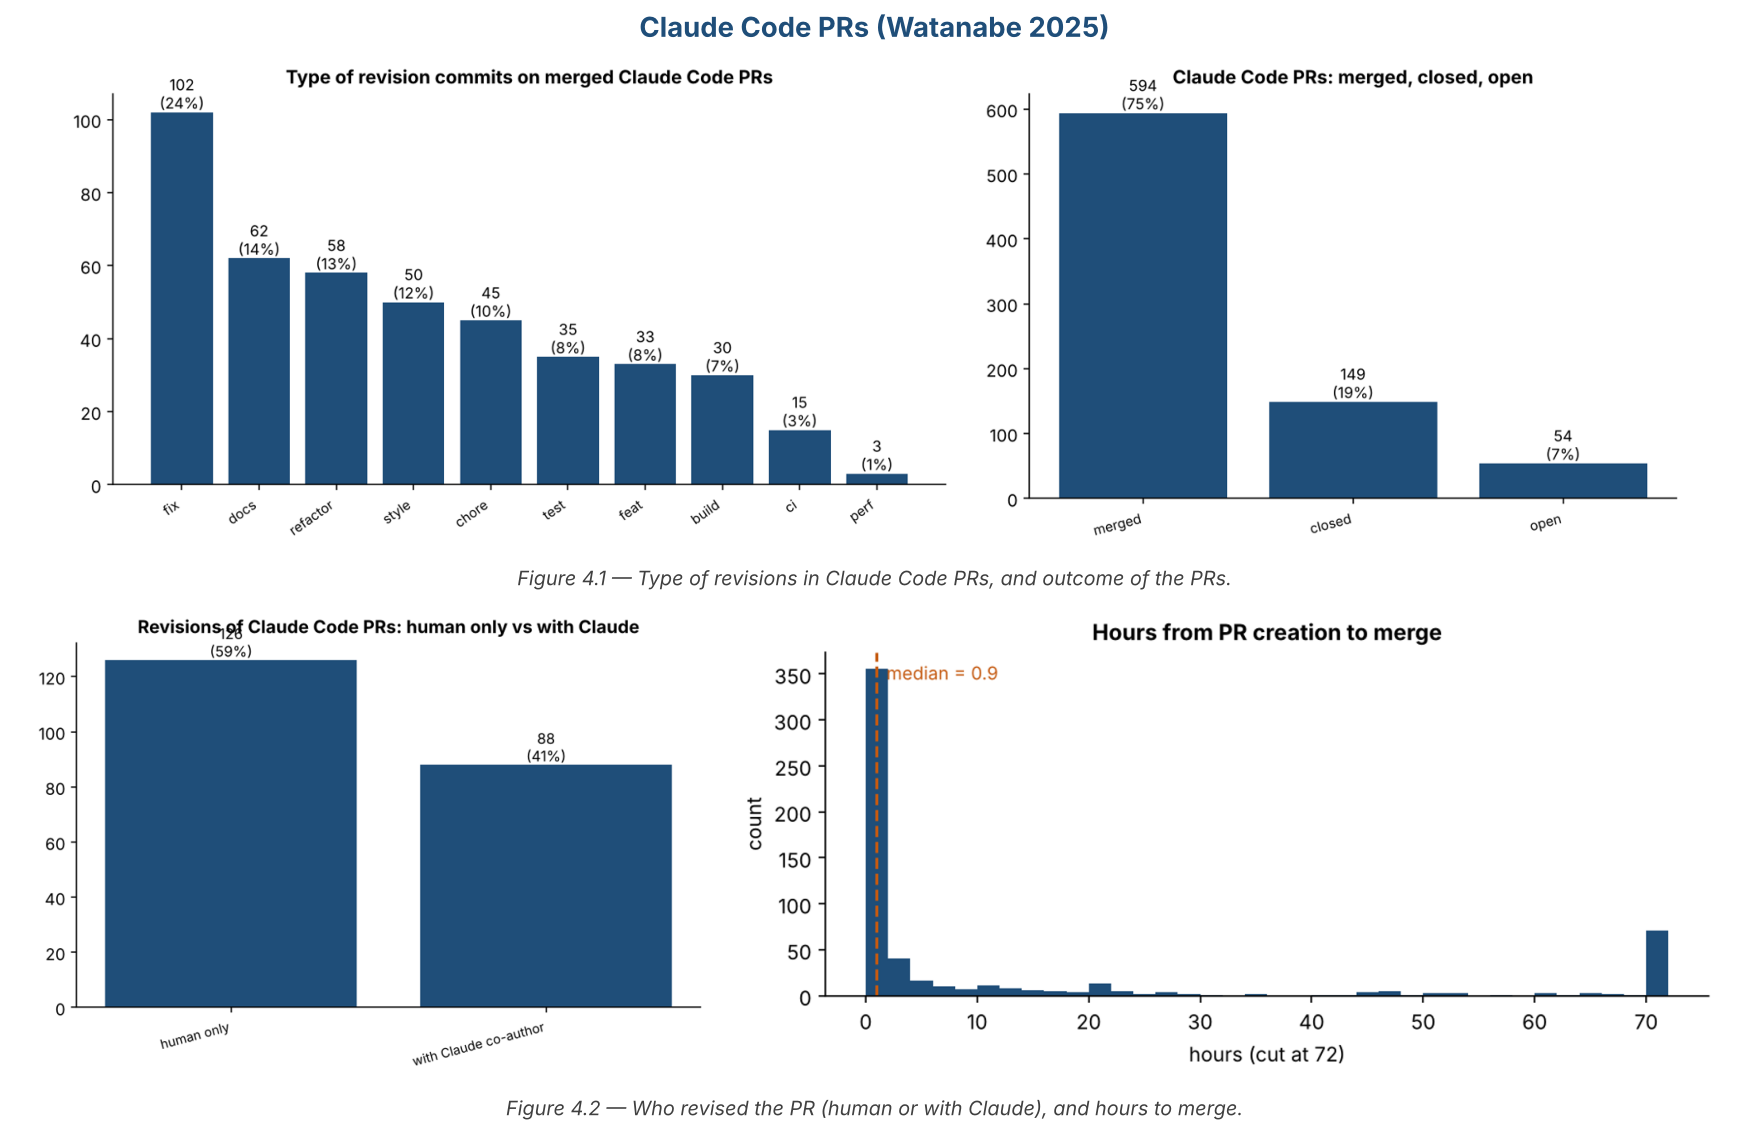

In [15]:
final_figure(4, "Claude Code PRs (Watanabe 2025)",
             "Type of revisions in Claude Code PRs, and outcome of the PRs.",
             "Who revised the PR (human or with Claude), and hours to merge.")

## 5. The fixes in one common format
Each row = one **revision commit labelled `fix`** on a merged Claude Code PR. The commit message, date and changed files come from `Data/commit_details/APR-commit-details.csv`. (In `Revision-APR(RQ4).csv` the columns `url` and `pull_number` are swapped.)

The notebook `99_ALL_PAPERS_summary` merges this file from every paper into the **final dataset**.

In [16]:
lab_rows = labels[labels[[f"label{i}" for i in range(1, 8)]].eq("fix").any(axis=1)].copy()
lab_rows["pr_url"] = lab_rows["pull_number"].astype(str)
who = rev.set_index("url")["revised_by"].map({"human only": "Human", "with Claude co-author": "AI agent"})
cd = pd.read_csv(os.path.join(D, "commit_details", "APR-commit-details.csv"))
cd["key"] = cd["url"].astype(str) + "|" + cd["commit_sha"].astype(str).str[:7]
lab_rows["key"] = lab_rows["pr_url"] + "|" + lab_rows["sha"].astype(str).str[:7]
lab_rows = lab_rows.merge(cd.drop_duplicates("key")[["key", "commit_message", "commit_date", "changed_files", "pr_created_date"]], on="key", how="left")
days = (pd.to_datetime(lab_rows["commit_date"], utc=True, errors="coerce") - pd.to_datetime(lab_rows["pr_created_date"], utc=True, errors="coerce")).dt.total_seconds() / 86400
f = pd.DataFrame({"agent": "Claude Code", "repo": lab_rows["owner"] + "/" + lab_rows["repo_name"],
    "language": lab_rows["changed_files"].fillna("").str.split(",").map(lang_of), "level": "commit",
    "ai_change": lab_rows["pr_url"], "fix_change": lab_rows["sha"], "fixed_by": lab_rows["pr_url"].map(who).fillna("Unknown"),
    "days_to_fix": days.round(2), "fix_label": "fix (revision commit)",
    "fix_reason": lab_rows["commit_message"].fillna("").str.split("\n").str[0].replace("", None), "has_code_patch": False})
print("with message:", f.fix_reason.notna().sum(), "| with days:", f.days_to_fix.notna().sum(), "| median days:", f.days_to_fix.median())
fixes = save_fixes(f, "Watanabe 2025")

with message: 101 | with days: 102 | median days: 0.01


**102 fixes saved to `tables/fixes.csv`** (same columns in every paper)

,paper,fix_id,agent,repo,language,level,ai_change,fix_change,fixed_by,days_to_fix,fix_label,fix_reason,has_code_patch
0,Watanabe 2025,WAT-00000,Claude Code,567-labs/instructor,Python,commit,https://github.com/567-labs/instructor/pull/1375,48d144d,Human,0.00,fix (revision commit),test: add comprehensive tests for multimodal message han...,False
1,Watanabe 2025,WAT-00001,Claude Code,567-labs/instructor,Other,commit,https://github.com/567-labs/instructor/pull/1490,cdac903,AI agent,1.31,fix (revision commit),Delete docs/blog/posts/unified-provider.md,False
2,Watanabe 2025,WAT-00002,Claude Code,ApeWorX/ape,Python,commit,https://github.com/ApeWorX/ape/pull/2530,e682ac6,AI agent,11.81,fix (revision commit),feat: migrate to ruff for linting and formatting,False
3,Watanabe 2025,WAT-00003,Claude Code,E3SM-Project/e3sm_diags,Python,commit,https://github.com/E3SM-Project/e3sm_diags/pull/963,20d74dc,Human,0.02,fix (revision commit),fixing pre-commiting,False
4,Watanabe 2025,WAT-00004,Claude Code,INCATools/ontology-access-kit,Python,commit,https://github.com/INCATools/ontology-access-kit/pull/831,e34b002,AI agent,0.03,fix (revision commit),Fix linting issues in test_ols.py,False
